# Composite Index
Greatly inspired by S&P500 model. Reason to create composite index based on the fact that RSI_SMA_DIST is white noise where mean lies at 0 and variance is heteroskedastic. Accept that it cannot be predicted. Instead, we want to create a composite index where mean has a certain bias (upside)
- RSI(14) - SMA(14) mean is either > 20 or < 20.
- Best result: Finding a mean such that when subtracted by variance, it still stays > 0.

Three possible approaches:
- Let assets with RSI(14) - SMA(14) > 0 run. Cut out assets with RSI(14) - SMA(14) < 0.
- Let assets that score strong trend in HMM run. Cut out assets that is no longer in a strong trend.
- Create multi-variate synthetic asset. Use kalman with frozen beta for stability or use LAsSO so it can default losers to 0 and let winners run.

In [3]:
# Add the project root (one level up from /research) to the path
import sys
import os

sys.path.append(os.path.abspath(os.path.join(os.getcwd(), '..')))

# Libraries needed to run the code
from utils.bybit import BybitConnector
from utils.screener import *

client = BybitConnector(api_key="", api_secret="", testnet=False)

# Testing out Screener
Result shows that no asset has a strong bias to one side. Meaning, it confirms the fact that we need to create a synthetic asset. At minimum, bias_std2 - bias > 0 or < 0 which means assumption-wise 95% of the time asset remains on one side of the trend.

In [2]:
# 1. Get your raw data
screened_data = screener(client)

# 2. Get the ranked table
ranked_df = rank_bias(screened_data)

# 3. Print the Top 10 strongest trending assets
print("--- Top 10 Assets by Bias Intensity ---")
print(ranked_df.head(10))

# 4. Optional: Filter for specific directional bias
strong_bullish = ranked_df[ranked_df['bias'] > 0].head(5)
strong_bearish = ranked_df[ranked_df['bias'] < 0].head(5)

NameError: name 'screener' is not defined

# Composite Index

Total tickers: 2710 | After filtering: 612
Error on HEI/USDT:USDT: CCXT / Bybit API Error: bybit {"retCode":10006,"retMsg":"Too many visits. Exceeded the API Rate Limit.","result":{},"retExtInfo":{},"time":1783402207666}
Error on HEMI/USDT:USDT: CCXT / Bybit API Error: bybit {"retCode":10006,"retMsg":"Too many visits. Exceeded the API Rate Limit.","result":{},"retExtInfo":{},"time":1783402208665}
Error on HNT/USDT:USDT: CCXT / Bybit API Error: bybit {"retCode":10006,"retMsg":"Too many visits. Exceeded the API Rate Limit.","result":{},"retExtInfo":{},"time":1783402212352}
Error on HOME/USDT:USDT: CCXT / Bybit API Error: bybit {"retCode":10006,"retMsg":"Too many visits. Exceeded the API Rate Limit.","result":{},"retExtInfo":{},"time":1783402213620}
Error on H/USDT:USDT: CCXT / Bybit API Error: bybit {"retCode":10006,"retMsg":"Too many visits. Exceeded the API Rate Limit.","result":{},"retExtInfo":{},"time":1783402216224}
Error on ICNT/USDT:USDT: CCXT / Bybit API Error: bybit {"retCode":1

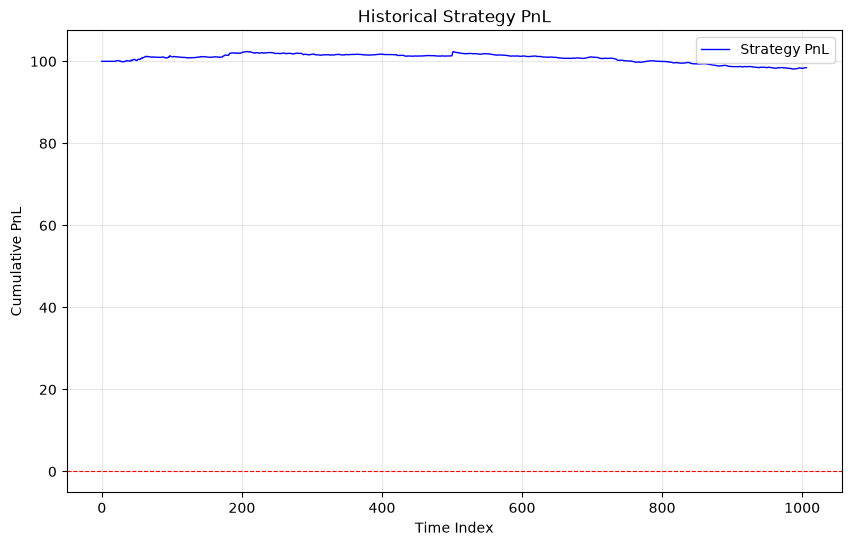

In [4]:
# Wire this up to however you build your connector elsewhere in your
# codebase (same object screener.screener() expects).
from utils.screener import screener
from utils.composite import *
from utils.bybit import BybitConnector  # <-- adjust to your actual class name

connector = BybitConnector()
screened_data = screener(client)

composite_df, membership, active = build_composite(screened_data, period=7)
bias, rsi_sma_dist = test_composite_persistency(composite_df)

print(f"Candidate assets: {len(screened_data)}")
print(f"Current constituents: {int(active.iloc[-1].sum())}")
print(f"Composite's own 200-bar trend-persistency bias: {bias[-1]:.4f}")

changes = membership_changes(membership)
print(changes.tail(20))

plot_one(composite_df['close'])

In [ ]:
# --- 6. Technical Indicators ---
price_clean = np.asanyarray(composite_df['close'], dtype=float)
diffs = np.diff(price_clean)

# Calculate the raw RSI arrays
rsi_14_raw = get_wilders_rsi(diffs, 14)
rsi_14_sma_raw = sma(rsi_14_raw, 14)
rsi_2_raw = get_wilders_rsi(diffs, 2)

# Create full-length arrays filled with NaN
# Note: len(composite_df) is the total number of rows.
# The RSI calculations produce (len - 1) values because they rely on np.diff().
rsi_14 = np.full(len(composite_df), np.nan)
rsi_14_sma = np.full(len(composite_df), np.nan)
rsi_2 = np.full(len(composite_df), np.nan)

# Align arrays to the end
# Since np.diff() creates an array one shorter than the price array,
# we map them to the last (N-1) positions of our full-length array.
rsi_14[-(len(rsi_14_raw)):] = rsi_14_raw
rsi_14_sma[-(len(rsi_14_sma_raw)):] = rsi_14_sma_raw
rsi_2[-(len(rsi_2_raw)):] = rsi_2_raw # FIX: Use rsi_2_raw here, not rsi_2

# Assign to DataFrame
composite_df['rsi_2'] = rsi_2
composite_df['rsi_14'] = rsi_14
composite_df['sma_14'] = rsi_14_sma

import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Ensure your data is the last 1000 ticks
df_plot = composite_df

# Create Subplots: Price (top), RSI 14 (mid), RSI 2 (bottom)
fig = make_subplots(rows=3, cols=1, shared_xaxes=True, 
                    vertical_spacing=0.05, 
                    subplot_titles=('BTCUSDT Price', 'RSI 14', 'RSI 2'),
                    row_width=[0.2, 0.2, 0.6])

# --- Price Plot ---
fig.add_trace(go.Scatter(x=df_plot.index, y=df_plot['close'], name='Price', line=dict(color='black', width=1)), row=1, col=1)

# --- RSI 14 Plot ---
fig.add_trace(go.Scatter(x=df_plot.index, y=df_plot['rsi_14'], name='RSI 14', line=dict(color='blue', width=1)), row=2, col=1)
fig.add_trace(go.Scatter(x=df_plot.index, y=df_plot['sma_14'], name='SMA 14', line=dict(color='orange', width=1)), row=2, col=1)

# --- RSI 2 Plot ---
fig.add_trace(go.Scatter(x=df_plot.index, y=df_plot['rsi_2'], name='RSI 2', line=dict(color='purple', width=1)), row=3, col=1)

# Add Threshold lines
fig.add_hline(y=70, line_dash="dash", line_color="red", row=2, col=1)
fig.add_hline(y=30, line_dash="dash", line_color="green", row=2, col=1)
fig.add_hline(y=90, line_dash="dash", line_color="red", row=3, col=1)
fig.add_hline(y=10, line_dash="dash", line_color="green", row=3, col=1)

# Update layout for "Trading View" feel
fig.update_layout(
    height=800,
    template="plotly_white",
    hovermode="x unified", # Shows all values on hover
    xaxis_rangeslider_visible=False # Set to True if you want a slider at the bottom
)

fig.show()